b'Hello from the lab.' 
 01001000011001010110110001101100011011110010000001100110011100100110111101101101001000000111010001101000011001010010000001101100011000010110001000101110
19 bytes, 152 bits
38 symbols


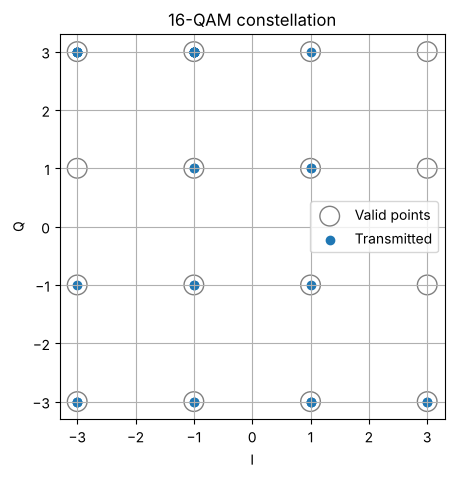

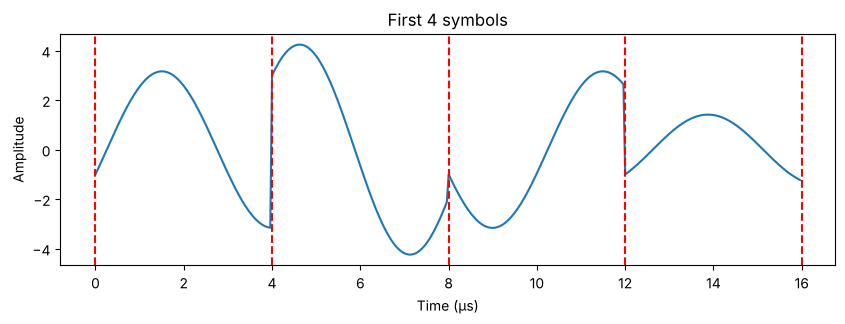

Ns = 100 | symbol rate = 250000.0 Bd | bit rate = 1000000.0 bit/s | cycles/symbol = 0.7999999999999999
[[-1.        -3.j         -0.40242546-2.96538764j]
 [ 3.        -3.j          3.40007956-3.69632202j]
 [-1.        +3.j         -1.49882705+3.33085483j]
 [-1.        -1.j         -0.76789266-0.86664015j]
 [-1.        +3.j         -1.49882705+3.33085483j]]
'Hello from the lab.' | bit errors: 0 | exact: True
20 dB: bit errors = 1, BER = 0.0066, exact = False, text = 'Hello$from the lab.'
10 dB: bit errors = 11, BER = 0.0724, exact = False, text = 'Hehl/%fr/m%th% h!b&'
0 dB: bit errors = 48, BER = 0.3158, exact = False, text = "\x0c#��*?��'+-��$��1b'"


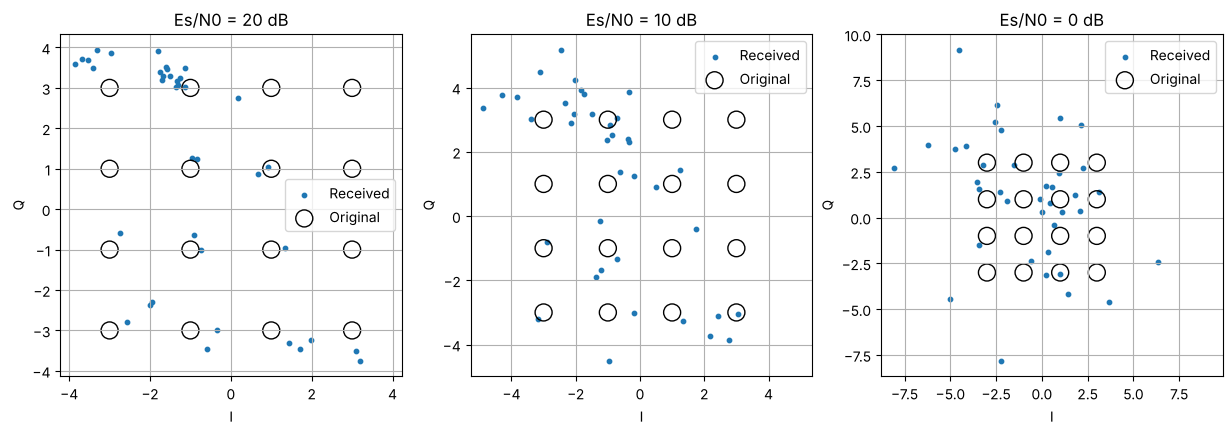

Attenuation x0.5: bit errors = 42, text = ']u}}\x7fuww\x7f}uu}uu}uw\x7f'
Multipath: bit errors = 1, text = 'Hello from the lcb.'


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Provided helpers (inlined so no extra file is needed)
def recover_symbols(rx, fc, fs, ns):
    t = np.arange(ns) / fs
    f = np.asarray(rx, float).reshape(-1, ns)
    return 2*np.mean(f*np.cos(2*np.pi*fc*t), 1) - 2j*np.mean(f*np.sin(2*np.pi*fc*t), 1)

def add_passband_awgn(sig, syms, ns, esn0_db, seed=2026):
    var = ns * np.mean(np.abs(syms)**2) / (4 * 10**(esn0_db/10))
    return sig + np.random.default_rng(seed).normal(0, np.sqrt(var), len(sig))

level_map = {'00': -3, '01': -1, '11': 1, '10': 3}
inv_map = {v: k for k, v in level_map.items()}
levels = np.array([-3, -1, 1, 3])

# 1. Text encoding
msg = "Hello from the lab."
b = msg.encode('utf-8')
bits = np.unpackbits(np.frombuffer(b, np.uint8))
print(b, '\n', ''.join(map(str, bits)))
print(len(b), 'bytes,', len(bits), 'bits')
# Receiver must use the same encoding: the bits only map back to the same characters under the same rule.

# 2. 16-QAM mapping
s = ''.join(map(str, bits))
syms = np.array([level_map[s[i:i+2]] + 1j*level_map[s[i+2:i+4]] for i in range(0, len(s), 4)])
print(len(syms), 'symbols')  # 16 = 2^4 points, so log2(16) = 4 bits per symbol
ref = np.array([i + 1j*q for i in levels for q in levels])
plt.figure(figsize=(5, 5))
plt.scatter(ref.real, ref.imag, s=200, facecolors='none', edgecolors='grey', label='Valid points')
plt.scatter(syms.real, syms.imag, label='Transmitted')
plt.xlabel('I'); plt.ylabel('Q'); plt.axis('square'); plt.grid(); plt.legend(); plt.title('16-QAM constellation'); plt.show()

# 3. Passband modulation
fc, fs, Ts = 0.2e6, 25e6, 4e-6
Ns = int(round(fs * Ts))            # 25e6 * 4e-6 = 100
t = np.arange(Ns) / fs
tx = (syms.real[:, None]*np.cos(2*np.pi*fc*t) - syms.imag[:, None]*np.sin(2*np.pi*fc*t)).ravel()
tt = np.arange(4*Ns) / fs * 1e6
plt.figure(figsize=(10, 3)); plt.plot(tt, tx[:4*Ns])
for k in range(5): plt.axvline(k*Ts*1e6, color='r', ls='--')
plt.xlabel('Time (µs)'); plt.ylabel('Amplitude'); plt.title('First 4 symbols'); plt.show()
print('Ns =', Ns, '| symbol rate =', 1/Ts, 'Bd | bit rate =', 4/Ts, 'bit/s | cycles/symbol =', fc*Ts)

# 4. Demodulation and text recovery
def decode(rx):
    I = levels[np.argmin(abs(rx.real[:, None] - levels), 1)]
    Q = levels[np.argmin(abs(rx.imag[:, None] - levels), 1)]
    rb = np.array([int(c) for i, q in zip(I, Q) for c in inv_map[i] + inv_map[q]], np.uint8)[:len(bits)]
    return rb, np.packbits(rb).tobytes().decode('utf-8', 'replace')

rx = recover_symbols(tx, fc, fs, Ns)
print(np.c_[syms[:5], rx[:5]])      # not exact: 0.8 cycles/symbol, but every error < 1, so decisions are still correct
rb, txt = decode(rx)
print(repr(txt), '| bit errors:', np.sum(rb != bits), '| exact:', txt == msg)

# 5. Channel noise
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, db in zip(ax, [20, 10, 0]):
    r = recover_symbols(add_passband_awgn(tx, syms, Ns, db), fc, fs, Ns)
    rb, txt = decode(r)
    e = np.sum(rb != bits)
    print(f'{db} dB: bit errors = {e}, BER = {e/len(bits):.4f}, exact = {txt == msg}, text = {txt!r}')
    a.scatter(r.real, r.imag, s=10, label='Received')
    a.scatter(ref.real, ref.imag, s=150, facecolors='none', edgecolors='k', label='Original')
    a.set(xlabel='I', ylabel='Q', title=f'Es/N0 = {db} dB'); a.axis('square'); a.grid(); a.legend()
plt.show()
# Noise shifts points; if it moves one past a decision boundary (1 unit away), the nearest point is a different symbol.

# Attenuation and multipath
for name, sig in [('Attenuation x0.5', 0.5*tx), ('Multipath', tx + 0.4*np.r_[np.zeros(25), tx[:-25]])]:
    rb, txt = decode(recover_symbols(sig, fc, fs, Ns))
    print(f'{name}: bit errors = {np.sum(rb != bits)}, text = {txt!r}')
# Attenuation shrinks the points inside the fixed thresholds; multipath adds ISI from the delayed echo.